# Dois dilemas em ensembles de classificadores
Estudo didático com dados sintéticos 2D. Partição estratificada 65/35. Sem seleção dinâmica ou ajuste de hiperparâmetros.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from pathlib import Path
plt.rcParams.update({'font.size': 13, 'figure.facecolor': 'white', 'axes.facecolor': 'white'})
OUT = Path('resultados_dilemas_svm')
OUT.mkdir(exist_ok=True)
def salvar(fig, nome):
    fig.savefig(OUT / nome, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()


## Dataset
Duas gaussianas, 220 instâncias, 16 rótulos trocados e quatro outliers adicionais. A mesma partição é usada nas duas figuras.

In [2]:
rng = np.random.default_rng(42)
X = np.vstack([rng.normal([-1,0],[.85,.85],(110,2)),rng.normal([1,0],[.85,.85],(110,2))])
y = np.repeat([0,1],110)
ruido = np.zeros(len(y),bool)
ruido[rng.choice(len(y),16,replace=False)] = True
y[ruido] = 1-y[ruido]
X = np.vstack([X, [[3.5,2.4],[3.3,-2.3],[-3.5,2.4],[-3.3,-2.3]]])
y = np.r_[y,0,0,1,1]
ruido = np.r_[ruido,[False]*4]
outlier = np.r_[[False]*220,[True]*4]
tr, te = train_test_split(np.arange(len(y)),test_size=.35,random_state=42,stratify=y)


## 1. Diversidade não garante qualidade
Embaralhamos separadamente os rótulos de treinamento para produzir modelos fracos de forma controlada. A discordância é a proporção de predições diferentes, em média entre pares. Double Fault mede erros simultâneos. O voto majoritário é avaliado no teste original. Este cenário não demonstra uma relação universal entre diversidade e acurácia.

Acurácias: [0.51898734 0.63291139 0.55696203] Discordância: 0.3966244725738397 Double Fault: 0.23206751054852323 Voto: 0.5822784810126582


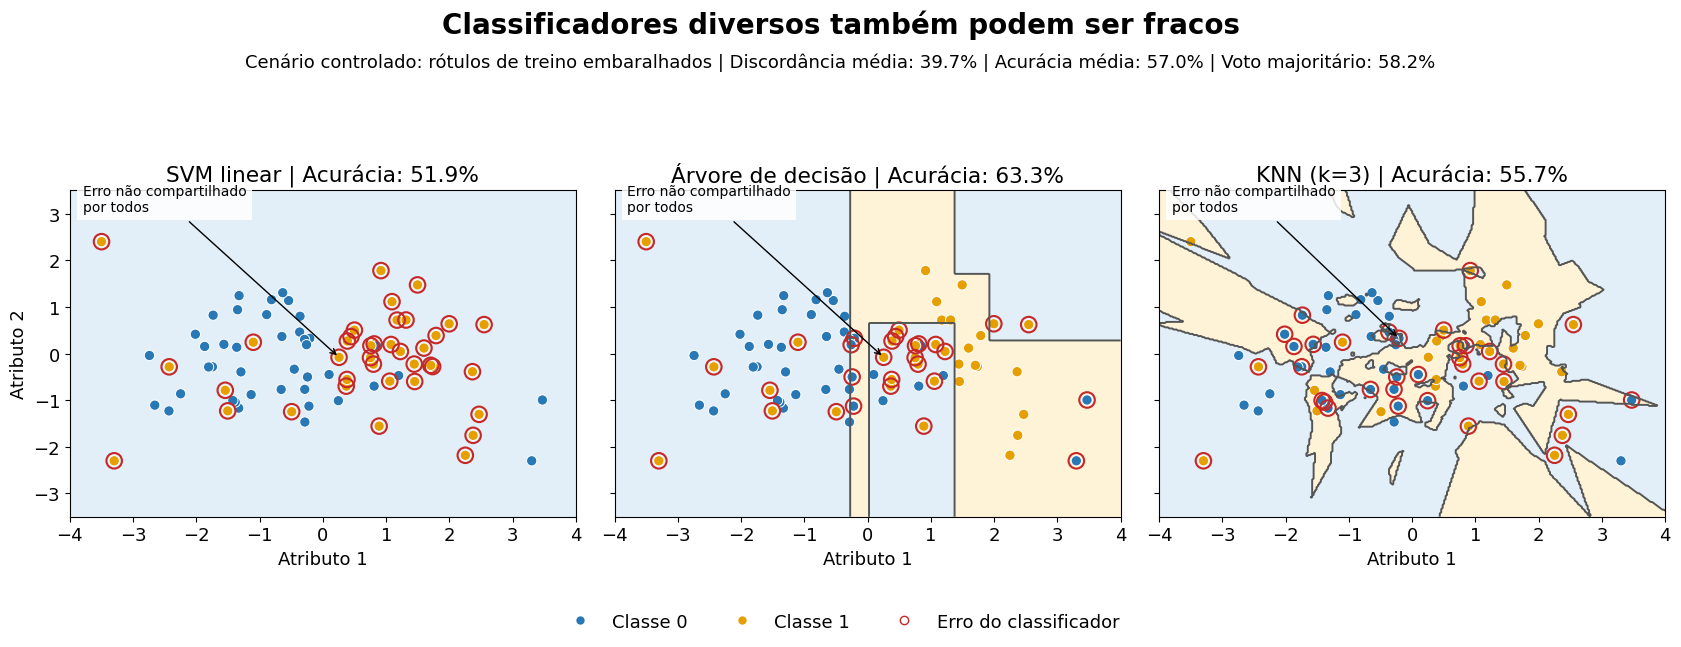

In [3]:
# Cenário controlado: classificadores treinados com rótulos de treino embaralhados.
# O teste permanece intacto. Não representa desempenho típico dos algoritmos.
weak_models = [SVC(kernel='linear', C=1.0), DecisionTreeClassifier(max_depth=3, random_state=42), KNeighborsClassifier(n_neighbors=3)]
weak_names = ['SVM linear', 'Árvore de decisão', 'KNN (k=3)']
for i, m in enumerate(weak_models):
    m.fit(X[tr], np.random.default_rng(10+i).permutation(y[tr]))
W = np.array([m.predict(X[te]) for m in weak_models])
wrong = W != y[te]
dis = np.mean([np.mean(W[i]!=W[j]) for i,j in [(0,1),(0,2),(1,2)]])
df = np.mean([np.mean(wrong[i]&wrong[j]) for i,j in [(0,1),(0,2),(1,2)]])
vote = (W.sum(axis=0)>=2).astype(int)
print('Acurácias:', 1-wrong.mean(axis=1), 'Discordância:',dis,'Double Fault:',df,'Voto:',np.mean(vote==y[te]))
xx, yy = np.meshgrid(np.linspace(-4,4,350),np.linspace(-3.5,3.5,300))
colors = np.array(['#2878b5','#e69f00'])
q = X[te]
fig, axes = plt.subplots(1,3,figsize=(17,6.5),sharex=True,sharey=True)
for i,(ax,m,name) in enumerate(zip(axes,weak_models,weak_names)):
    z=m.predict(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx,yy,z,levels=[-.5,.5,1.5],cmap=ListedColormap(['#dcebf7','#fff0ce']),alpha=.8)
    if np.unique(z).size>1: ax.contour(xx,yy,z,levels=[.5],colors='#555',linewidths=1.4)
    ax.scatter(*q.T,c=colors[y[te]],s=55,edgecolors='white',linewidths=.7)
    ax.scatter(*q[wrong[i]].T,facecolors='none',edgecolors='#c62828',s=125,linewidths=1.5)
    ids=np.flatnonzero(wrong[i] & (wrong.sum(axis=0)<3))
    if len(ids):
        j=ids[np.argmin(np.linalg.norm(q[ids]-[0,0],axis=1))]
        ax.annotate('Erro não compartilhado\npor todos',xy=q[j],xytext=(-3.8,3.05),fontsize=10,arrowprops={'arrowstyle':'->'},bbox={'facecolor':'white','alpha':.85,'edgecolor':'none'})
    ax.set(title=f'{name} | Acurácia: {1-wrong[i].mean():.1%}',xlabel='Atributo 1',xlim=(-4,4),ylim=(-3.5,3.5))
axes[0].set_ylabel('Atributo 2')
fig.suptitle('Classificadores diversos também podem ser fracos',fontsize=20,weight='bold')
fig.text(.5,.89,f'Cenário controlado: rótulos de treino embaralhados | Discordância média: {dis:.1%} | Acurácia média: {1-wrong.mean():.1%} | Voto majoritário: {np.mean(vote==y[te]):.1%}',ha='center',fontsize=13)
fig.legend(handles=[Line2D([],[],marker='o',color='none',markerfacecolor=c,markeredgecolor='none',label=f'Classe {i}') for i,c in enumerate(colors)]+[Line2D([],[],marker='o',color='none',markeredgecolor='#c62828',markerfacecolor='none',label='Erro do classificador')],loc='lower center',ncol=3,frameon=False)
fig.tight_layout(rect=[0,.09,1,.85])
salvar(fig,'01_diversidade_classificadores_fracos.png')

## 2. Natureza condicional do erro
Treinamos SVM e árvore com os rótulos originais do dataset sintético (incluindo o ruído inserido). A faixa cinza indica sobreposição aproximada; o sinal + indica proximidade à fronteira por perturbação local. Os contornos indicam erros de um ou ambos os modelos. Isso motiva seleção dinâmica, mas não estima competência local.

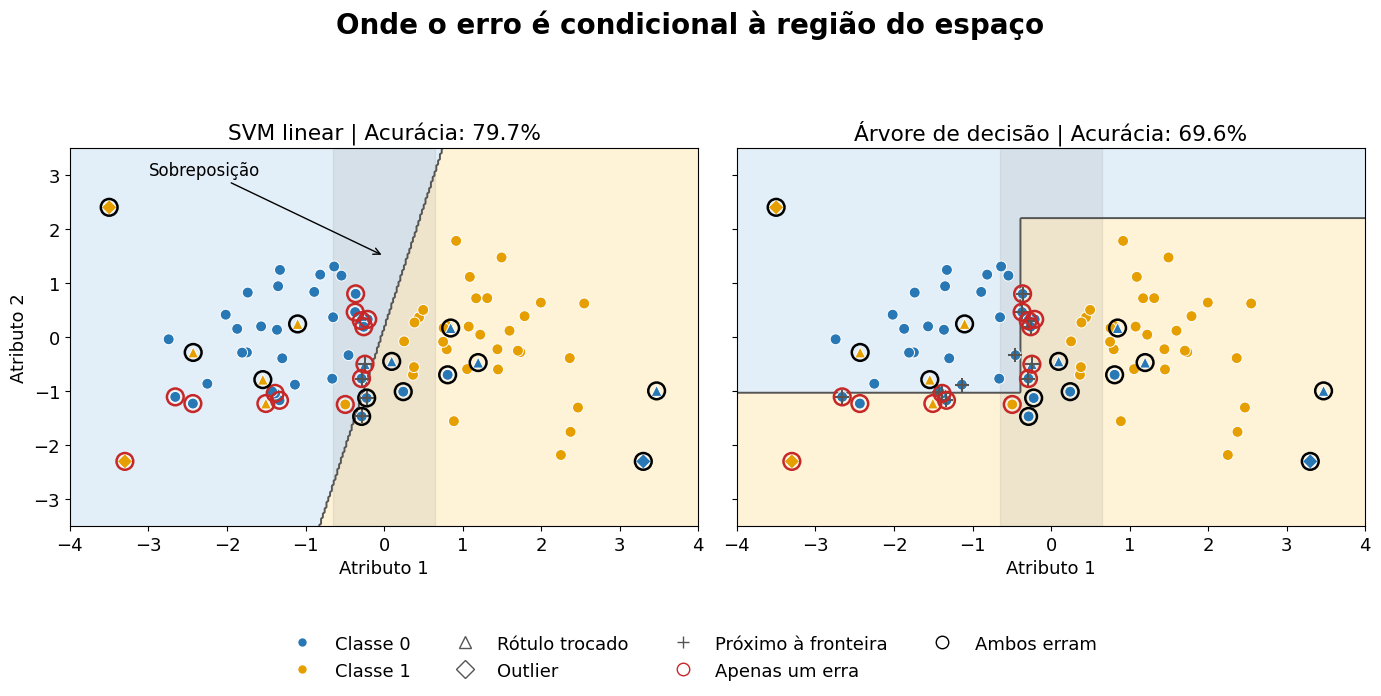

Instâncias de teste: 79 | Ruído: 9 | Outliers: 3


In [4]:
models = [SVC(kernel="linear", C=1.0), DecisionTreeClassifier(max_depth=3,random_state=42)]
for m in models: m.fit(X[tr],y[tr])
P = np.array([m.predict(X[te]) for m in models])
errors = (P != y[te]).sum(axis=0)
xx,yy = np.meshgrid(np.linspace(-4,4,350),np.linspace(-3.5,3.5,300))
fig, axes = plt.subplots(1,2,figsize=(14,7),sharex=True,sharey=True)
colors = np.array(['#2878b5','#e69f00'])
for ax,m,name in zip(axes,models,['SVM linear','Árvore de decisão']):
    z=m.predict(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx,yy,z,levels=[-.5,.5,1.5],cmap=ListedColormap(['#dcebf7','#fff0ce']),alpha=.8)
    ax.contour(xx,yy,z,levels=[.5],colors='#555555',linewidths=1.4)
    ax.axvspan(-.65,.65,color='#777777',alpha=.12)
    q=X[te]; base=m.predict(q)
    offsets=.16*np.c_[np.cos(np.linspace(0,2*np.pi,16,endpoint=False)),np.sin(np.linspace(0,2*np.pi,16,endpoint=False))]
    near=np.any(np.array([m.predict(q+d)!=base for d in offsets]),axis=0)
    for mask,marker in [(~ruido[te]&~outlier[te],'o'),(ruido[te],'^'),(outlier[te],'D')]:
        ax.scatter(*q[mask].T,c=colors[y[te][mask]],marker=marker,s=62,edgecolors='white',linewidths=.7,zorder=3)
    ax.scatter(*q[near].T,marker='+',c='#555555',s=100,zorder=4)
    for k,c in [(1,'#c62828'),(2,'black')]:
        ax.scatter(*q[errors==k].T,facecolors='none',edgecolors=c,s=145,linewidths=1.8,zorder=5)
    ax.set(title=f'{name} | Acurácia: {np.mean(base==y[te]):.1%}',xlabel='Atributo 1',xlim=(-4,4),ylim=(-3.5,3.5))
axes[0].set_ylabel('Atributo 2')
axes[0].annotate('Sobreposição',xy=(0,1.5),xytext=(-3,3),arrowprops={'arrowstyle':'->'},fontsize=12)
handles=[Line2D([],[],marker='o',color='none',markerfacecolor=c,markeredgecolor='none',label=f'Classe {i}') for i,c in enumerate(colors)]
handles += [Line2D([],[],marker=m,color='none',markeredgecolor=c,markerfacecolor='none',markersize=9,label=l) for m,c,l in [('^','#555','Rótulo trocado'),('D','#555','Outlier'),('+','#555','Próximo à fronteira'),('o','#c62828','Apenas um erra'),('o','black','Ambos erram')]]
fig.legend(handles=handles,loc='lower center',ncol=4,frameon=False)
fig.suptitle('Onde o erro é condicional à região do espaço',fontsize=20,weight='bold')
fig.tight_layout(rect=[0,.14,1,.92])
salvar(fig,'02_erro_condicional.png')
print('Instâncias de teste:',len(te),'| Ruído:',ruido[te].sum(),'| Outliers:',outlier[te].sum())